# 01 - Preprocessing & EDA

Khám phá dữ liệu Hotel Booking Demand, kiểm tra chất lượng dữ liệu, xử lý dữ liệu và chuẩn bị train/test split dùng chung cho cả 3 mô hình.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

from src.preprocessing import (
    CATEGORICAL_FEATURES, FEATURES, LEAKAGE_COLUMNS, NUMERIC_FEATURES, TARGET,
    build_preprocessor, clean_data, data_quality_report, engineer_features,
    get_feature_names, load_data, prepare_data,
)
from src.evaluation import save_figure

## 1. Tổng quan dataset

In [2]:
df = load_data()
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


## 2. Missing values, duplicates và giá trị bất thường

In [5]:
report = data_quality_report(df)
report[report["missing"] > 0]

,missing,missing_pct,dtype,n_unique
company,112593,94.31,float64,352
agent,16340,13.69,float64,333
country,488,0.41,str,177
children,4,0.00,float64,5


In [6]:
print("Số dòng trùng lặp:", df.duplicated().sum())
print("ADR âm:", (df["adr"] < 0).sum())
print("ADR > 1000:", (df["adr"] > 1000).sum())
print("Booking 0 khách:", ((df["adults"] + df["children"].fillna(0) + df["babies"]) == 0).sum())
print("Booking 0 đêm:", ((df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0).sum())

Số dòng trùng lặp: 31994
ADR âm: 1
ADR > 1000: 1
Booking 0 khách: 180
Booking 0 đêm: 715


**Nhận xét:**

- `company` thiếu ~94%, `agent` thiếu ~14% → không dùng ID trực tiếp mà tạo đặc trưng nhị phân `has_company`, `has_agent`.
- `country` thiếu 488 dòng, `children` thiếu 4 dòng → impute (mode / median) bên trong pipeline, fit trên tập train.
- Có ~32.000 dòng trùng lặp. Nếu giữ lại, cùng một booking có thể nằm ở cả train và test → kết quả bị đánh giá quá cao. Nhóm loại bỏ duplicates.
- Loại các dòng bất thường: ADR âm hoặc quá lớn, booking 0 khách, booking 0 đêm.

## 3. Phân tích biến mục tiêu

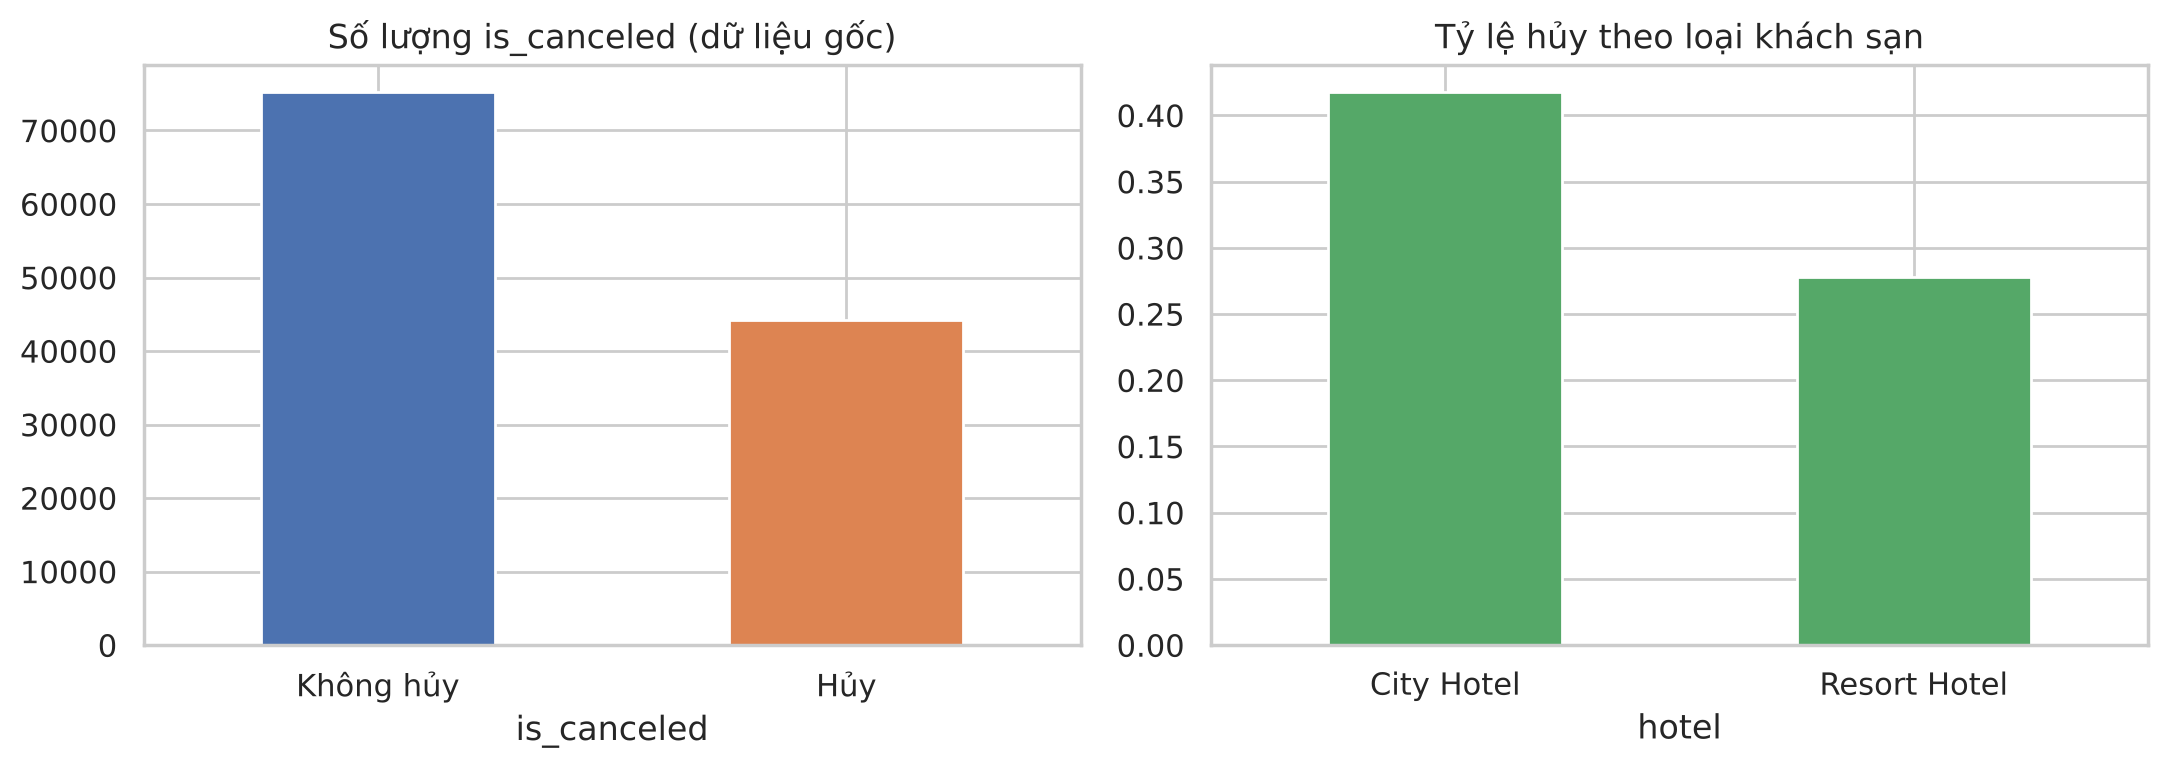

is_canceled
0    0.6296
1    0.3704
Name: proportion, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df[TARGET].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Số lượng is_canceled (dữ liệu gốc)")
axes[0].set_xticklabels(["Không hủy", "Hủy"], rotation=0)
df.groupby("hotel")[TARGET].mean().plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("Tỷ lệ hủy theo loại khách sạn")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
save_figure(fig, "eda_target.png")
plt.show()
print(df[TARGET].value_counts(normalize=True).round(4))

## 4. Data leakage

`reservation_status` và `reservation_status_date` được ghi nhận **sau khi** booking đã hủy/check-out, nên chứa trực tiếp đáp án. `assigned_room_type` chỉ biết được khi khách đến nhận phòng. Các cột này bị loại khỏi features.

In [8]:
pd.crosstab(df["reservation_status"], df[TARGET])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


## 5. Phân tích các đặc trưng quan trọng

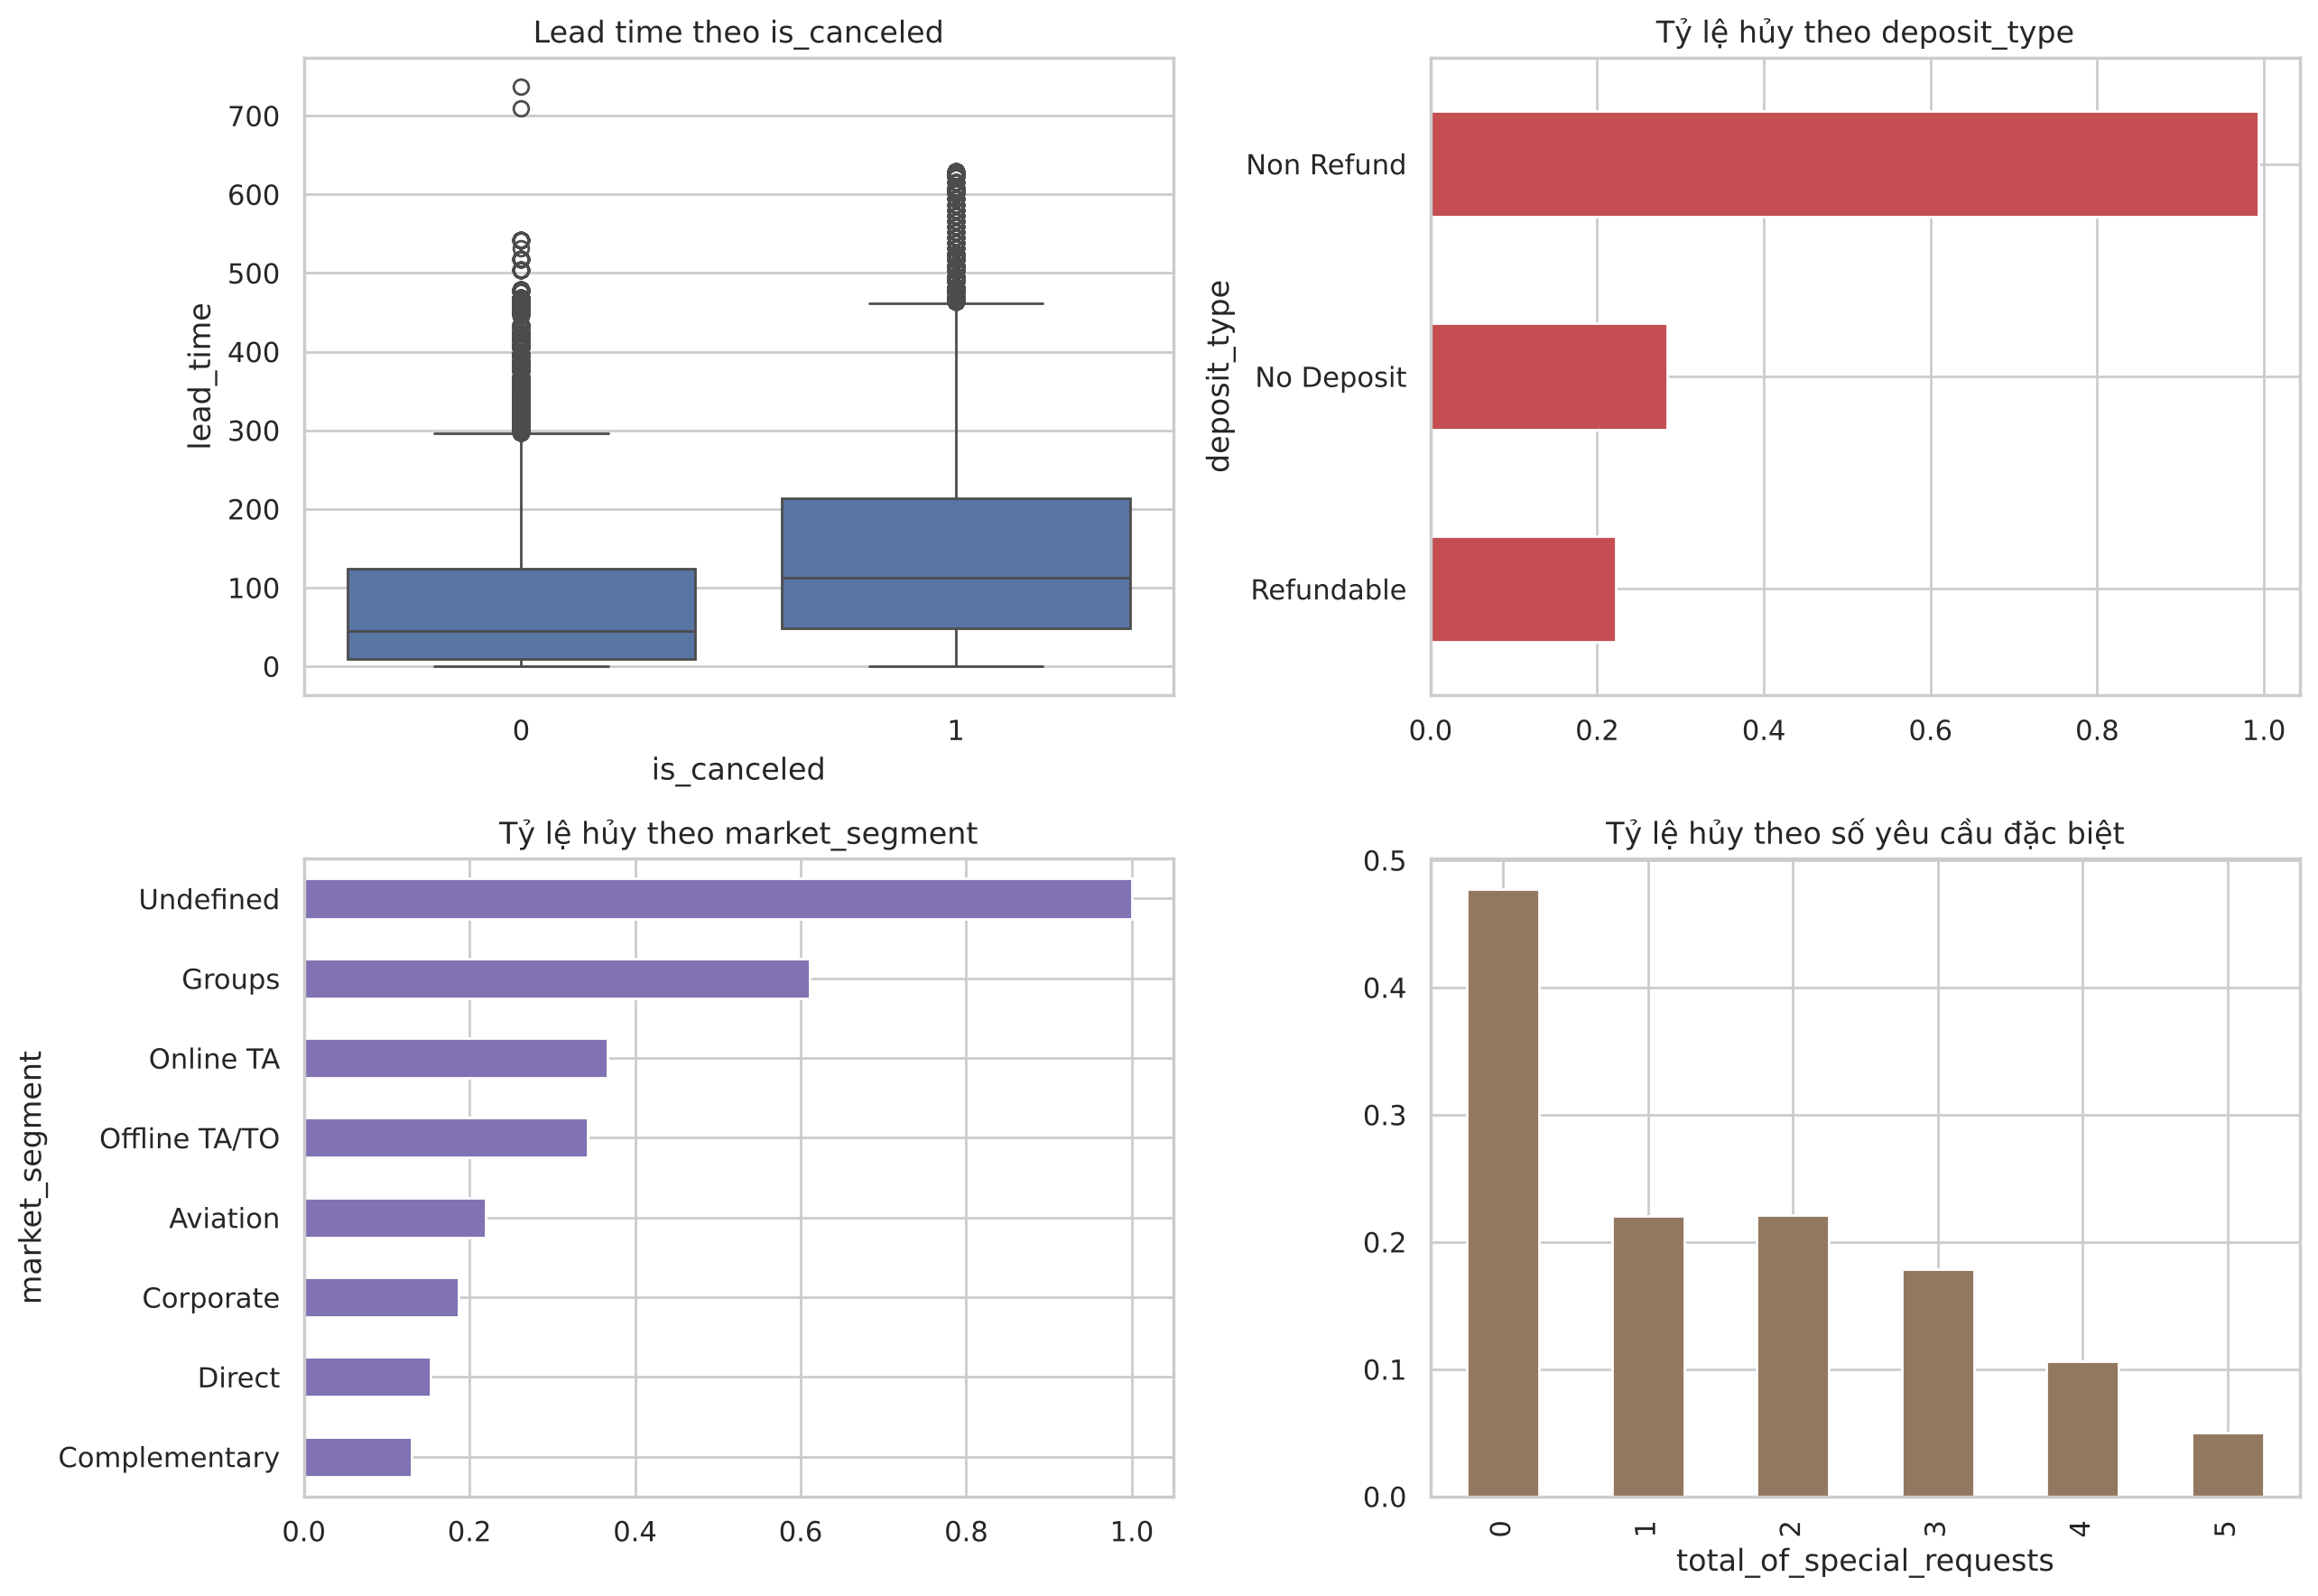

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.boxplot(data=df, x=TARGET, y="lead_time", ax=axes[0, 0])
axes[0, 0].set_title("Lead time theo is_canceled")
df.groupby("deposit_type")[TARGET].mean().sort_values().plot.barh(ax=axes[0, 1], color="#C44E52")
axes[0, 1].set_title("Tỷ lệ hủy theo deposit_type")
df.groupby("market_segment")[TARGET].mean().sort_values().plot.barh(ax=axes[1, 0], color="#8172B3")
axes[1, 0].set_title("Tỷ lệ hủy theo market_segment")
df.groupby("total_of_special_requests")[TARGET].mean().plot.bar(ax=axes[1, 1], color="#937860")
axes[1, 1].set_title("Tỷ lệ hủy theo số yêu cầu đặc biệt")
save_figure(fig, "eda_features.png")
plt.show()

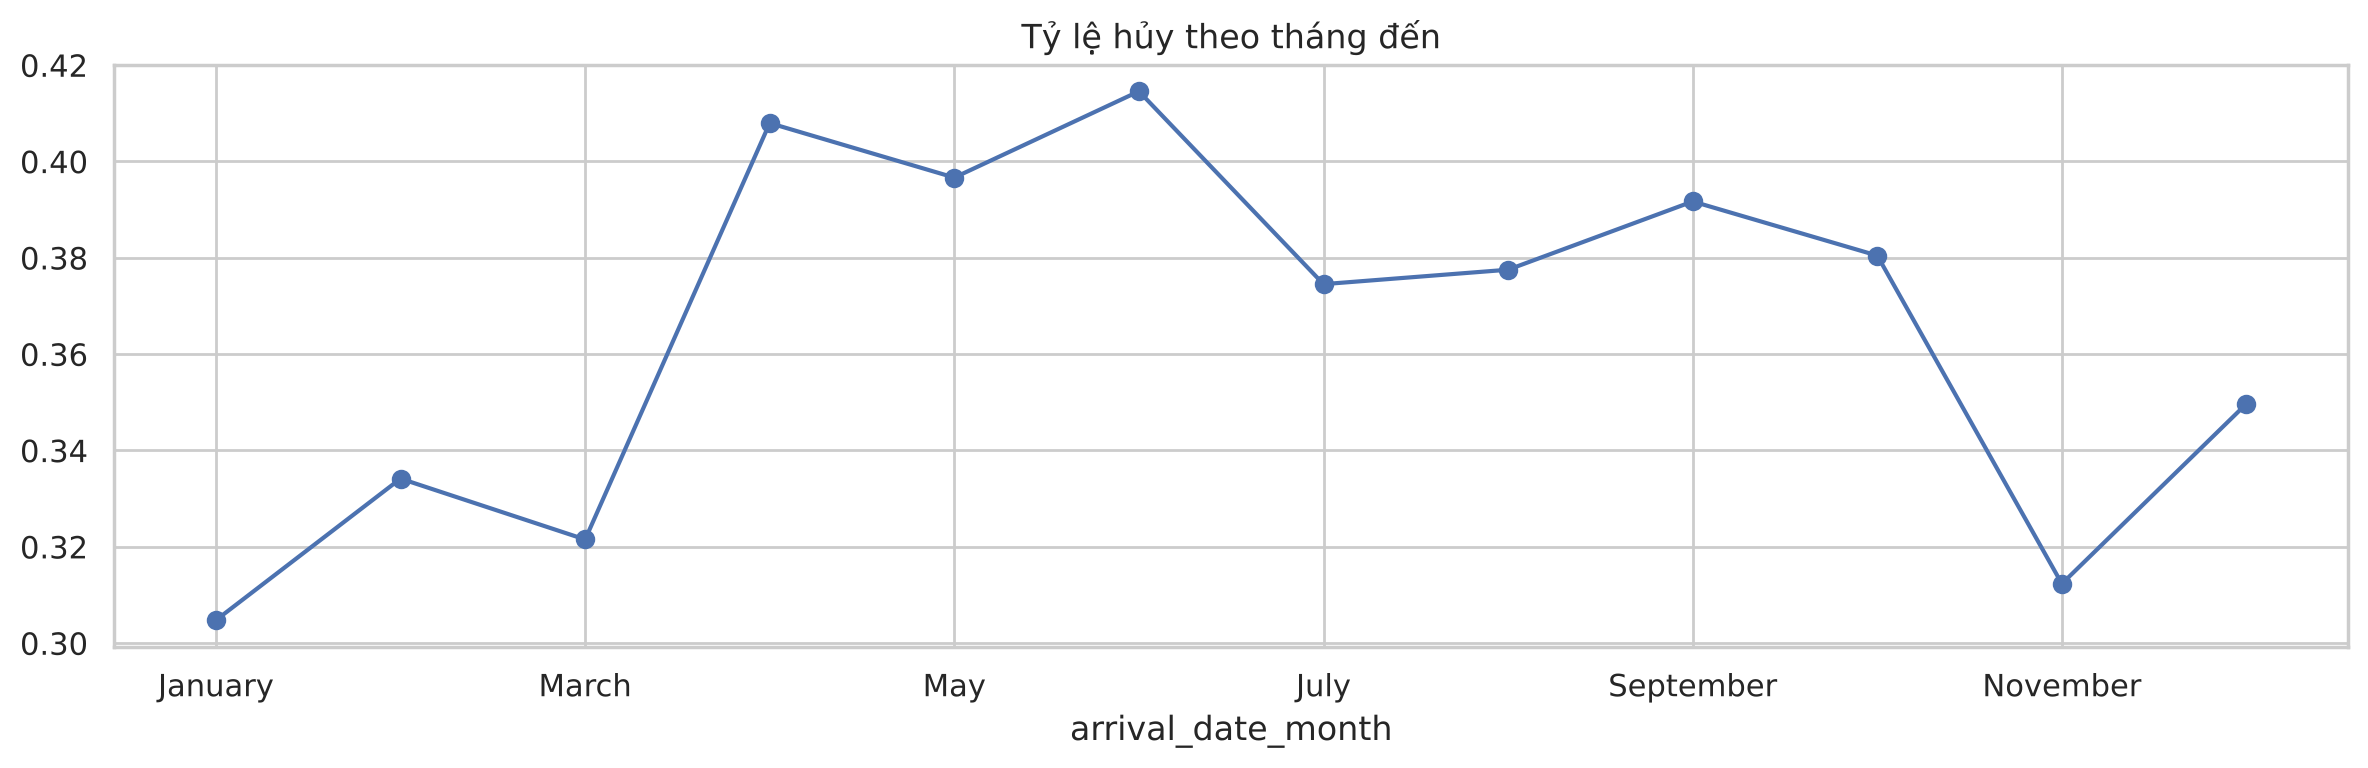

In [10]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
fig, ax = plt.subplots(figsize=(12, 4))
df.groupby("arrival_date_month")[TARGET].mean().reindex(months).plot(marker="o", ax=ax)
ax.set_title("Tỷ lệ hủy theo tháng đến")
save_figure(fig, "eda_month.png")
plt.show()

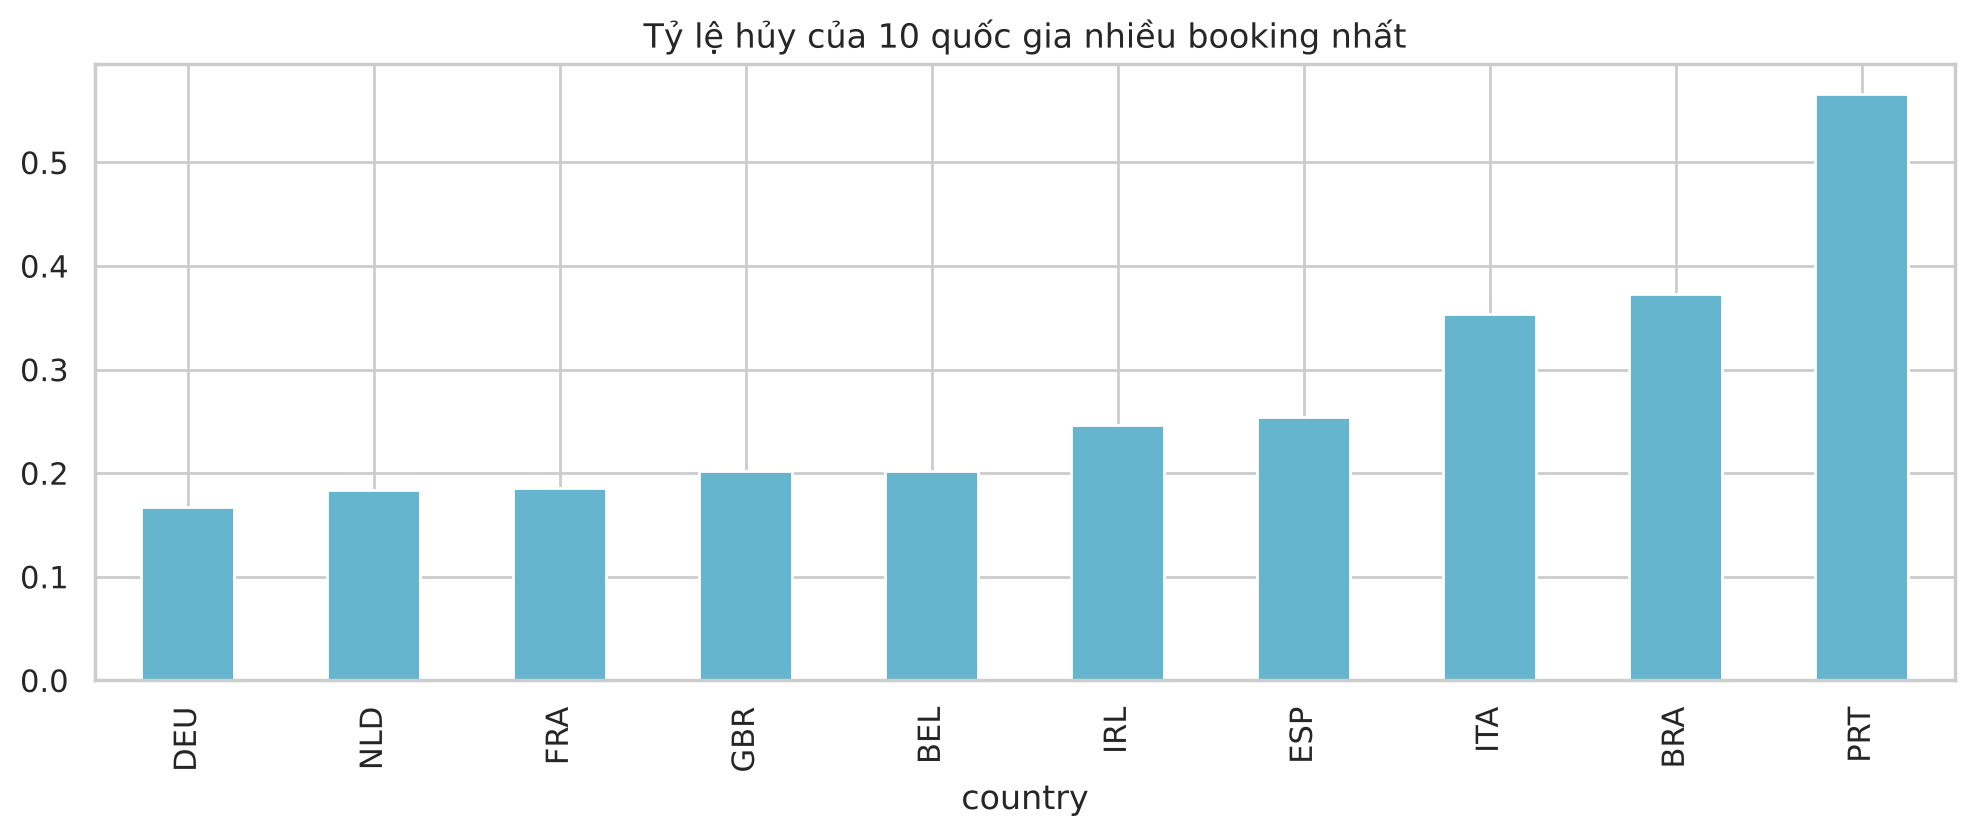

In [11]:
top_countries = df["country"].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(12, 4))
df[df["country"].isin(top_countries)].groupby("country")[TARGET].mean().sort_values().plot.bar(ax=ax, color="#64B5CD")
ax.set_title("Tỷ lệ hủy của 10 quốc gia nhiều booking nhất")
plt.show()

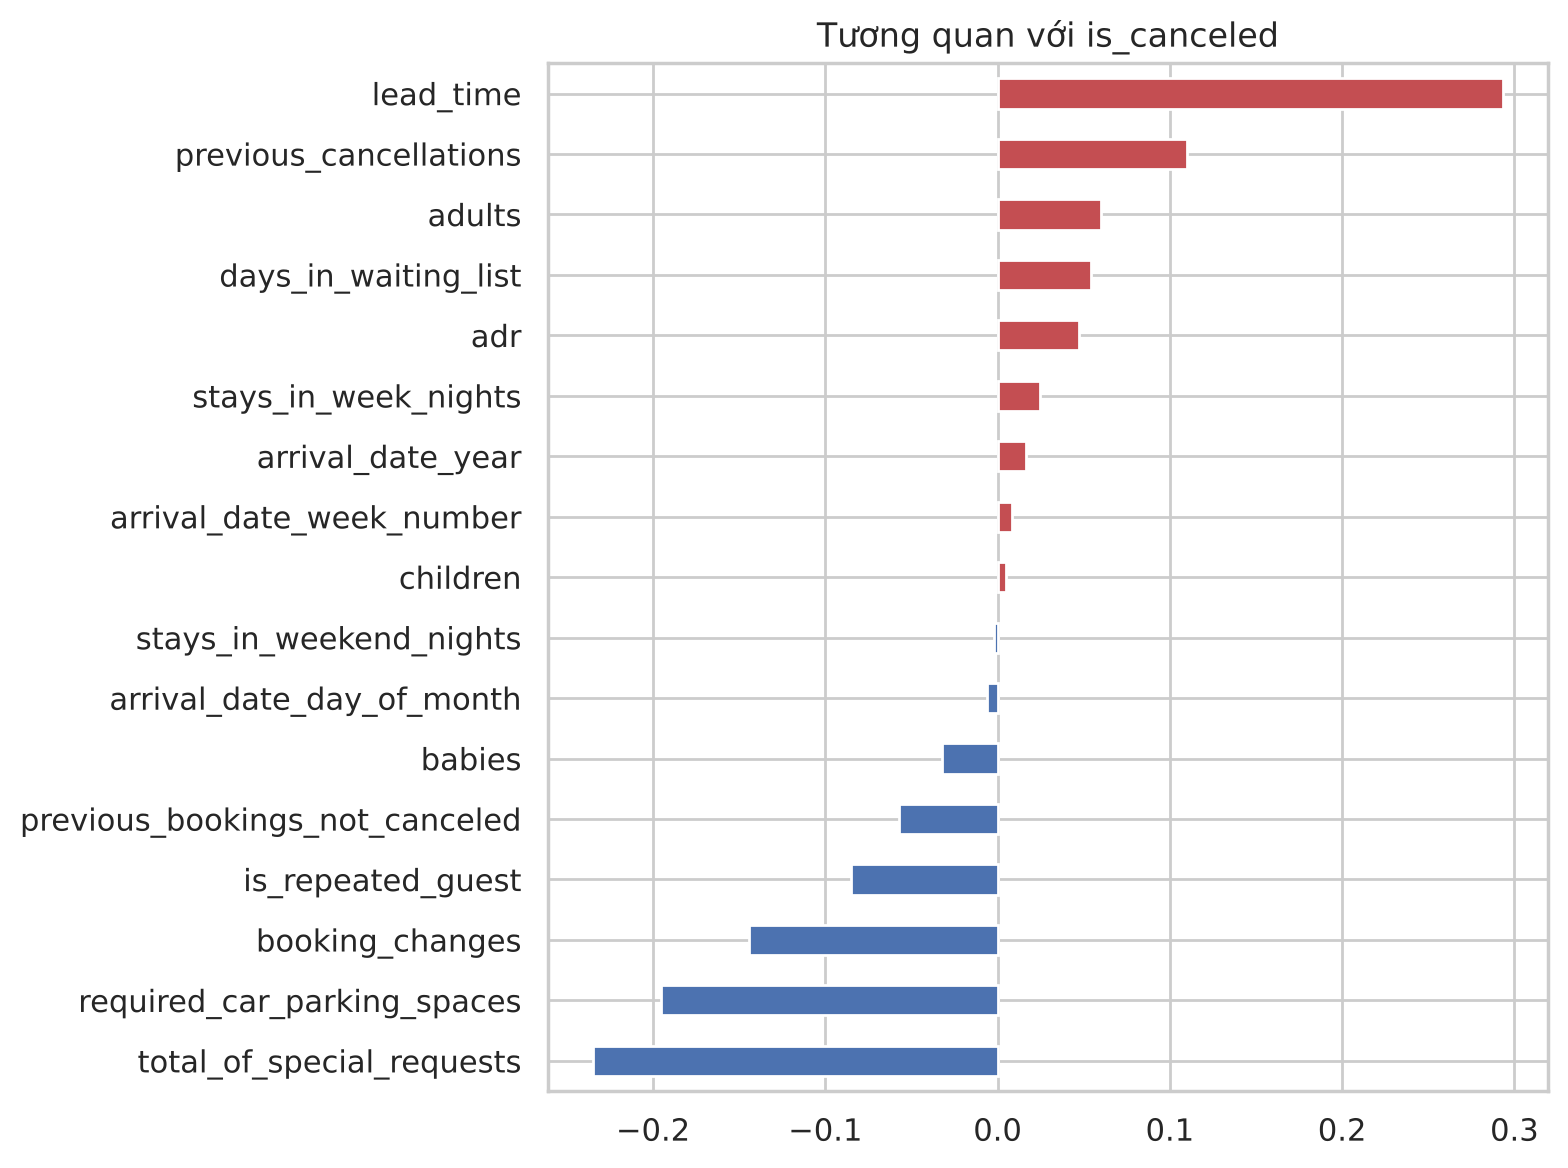

In [12]:
numeric = df.select_dtypes("number").drop(columns=["agent", "company"])
corr = numeric.corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "#C44E52", "#4C72B0"))
ax.set_title("Tương quan với is_canceled")
save_figure(fig, "eda_correlation.png")
plt.show()

**Nhận xét:** booking có `lead_time` dài, `deposit_type = Non Refund`, phân khúc `Groups`/`Online TA`, khách đến từ PRT có tỷ lệ hủy cao. Ngược lại, khách có yêu cầu đặc biệt, cần chỗ đậu xe hoặc là khách quen thì ít hủy hơn.

## 6. Làm sạch dữ liệu và feature engineering

In [13]:
clean = clean_data(df)
print("Trước:", df.shape, "Sau:", clean.shape, "Đã loại:", len(df) - len(clean))
features = engineer_features(clean)
features[["total_nights", "total_guests", "has_agent", "has_company", "is_family",
          "has_previous_cancel", "arrival_month", "month_sin", "month_cos"]].describe().T

Trước: (119390, 32) Sau: (86625, 32) Đã loại: 32765


,count,mean,std,min,25%,50%,75%,max
total_nights,86625.0,3.652999,2.735759,1.0,2.000000,3.000000e+00,5.0,69.0
total_guests,86625.0,2.026690,0.703344,1.0,2.000000,2.000000e+00,2.0,12.0
has_agent,86625.0,0.862038,0.344863,0.0,1.000000,1.000000e+00,1.0,1.0
has_company,86625.0,0.059683,0.236899,0.0,0.000000,0.000000e+00,0.0,1.0
is_family,86625.0,0.104646,0.306099,0.0,0.000000,0.000000e+00,0.0,1.0
has_previous_cancel,86625.0,0.019359,0.137785,0.0,0.000000,0.000000e+00,0.0,1.0
arrival_month,86625.0,6.471815,3.092466,1.0,4.000000,7.000000e+00,9.0,12.0
month_sin,86625.0,-0.043595,0.719414,-1.0,-0.866025,-2.449294e-16,0.5,1.0
month_cos,86625.0,-0.153932,0.675913,-1.0,-0.866025,-5.000000e-01,0.5,1.0


Các đặc trưng mới:

| Đặc trưng | Ý nghĩa |
|---|---|
| `total_nights` | Tổng số đêm lưu trú |
| `total_guests` | Tổng số khách |
| `has_agent`, `has_company` | Booking qua đại lý / công ty |
| `is_family` | Có trẻ em hoặc em bé |
| `has_previous_cancel` | Khách từng hủy phòng trước đó |
| `arrival_month`, `month_sin`, `month_cos` | Tháng đến dạng số và mã hóa chu kỳ |

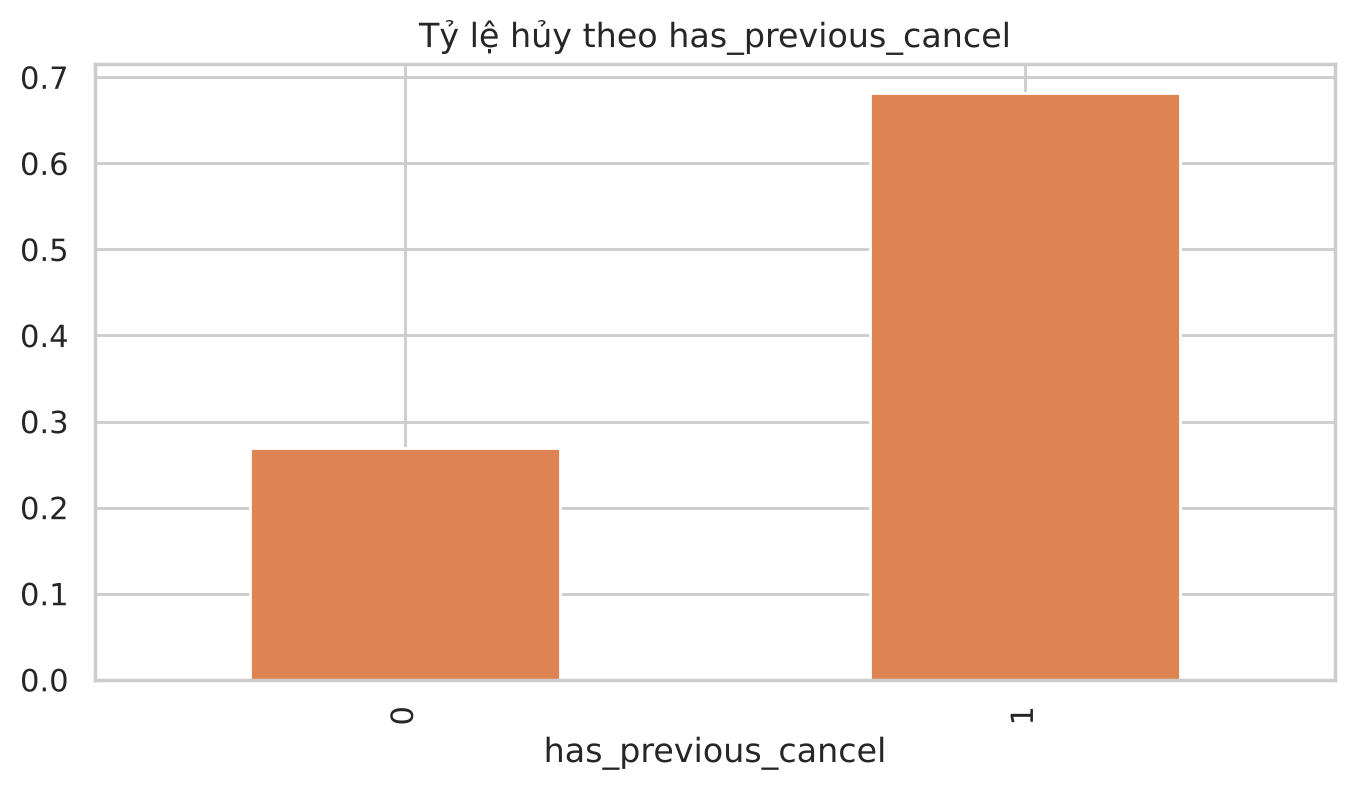

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
features.groupby("has_previous_cancel")[TARGET].mean().plot.bar(ax=ax, color="#DD8452")
ax.set_title("Tỷ lệ hủy theo has_previous_cancel")
plt.show()

## 7. Train/test split dùng chung

`test_size=0.2`, `random_state=42`, `stratify=y`. Imputation, encoding và scaling nằm trong `ColumnTransformer` → chỉ fit trên train, tránh data leakage.

In [15]:
X_train, X_test, y_train, y_test = prepare_data()
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Tỷ lệ hủy train:", round(y_train.mean(), 4), "test:", round(y_test.mean(), 4))
print("Numeric:", len(NUMERIC_FEATURES), "Categorical:", len(CATEGORICAL_FEATURES))

X_train: (69300, 32) X_test: (17325, 32)
Tỷ lệ hủy train: 0.2767 test: 0.2768
Numeric: 24 Categorical: 8


In [16]:
preprocessor = build_preprocessor(scale=True)
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)
print("Số features sau encoding:", X_train_t.shape[1])
get_feature_names(preprocessor)[-30:]

Số features sau encoding: 84


['country_SWE',
 'country_USA',
 'country_infrequent_sklearn',
 'market_segment_Complementary',
 'market_segment_Corporate',
 'market_segment_Direct',
 'market_segment_Groups',
 'market_segment_Offline TA/TO',
 'market_segment_Online TA',
 'market_segment_infrequent_sklearn',
 'distribution_channel_Corporate',
 'distribution_channel_Direct',
 'distribution_channel_TA/TO',
 'distribution_channel_infrequent_sklearn',
 'reserved_room_type_A',
 'reserved_room_type_B',
 'reserved_room_type_C',
 'reserved_room_type_D',
 'reserved_room_type_E',
 'reserved_room_type_F',
 'reserved_room_type_G',
 'reserved_room_type_H',
 'reserved_room_type_infrequent_sklearn',
 'deposit_type_No Deposit',
 'deposit_type_Non Refund',
 'deposit_type_infrequent_sklearn',
 'customer_type_Contract',
 'customer_type_Group',
 'customer_type_Transient',
 'customer_type_Transient-Party']